## Model Training

Goal is to train several classification models to predict churn (Exited)
and compare them to choose the best one.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
roc_auc_score, confusion_matrix, classification_report)

In [2]:
df = pd.read_csv("data/ChurnModel.csv")
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
X = df.drop(columns=["Exited"])
y = df["Exited"]
print(X.shape, y.shape)

(10000, 10) (10000,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print(f"Churn rate - train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")

(8000, 10) (2000, 10)
Churn rate - train: 0.204, test: 0.203


In [5]:
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
cat_cols = ["Geography", "Gender"]
bin_cols = ["HasCrCard", "IsActiveMember"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
print(X_train_p.shape)

(8000, 13)


In [6]:
def evaluate_model(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC_AUC": roc_auc_score(y_true, y_proba),
    }

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss"),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=False),
}

results = []
for name, model in models.items():
    model.fit(X_train_p, y_train)
    y_pred = model.predict(X_test_p)
    y_proba = model.predict_proba(X_test_p)[:, 1]
    scores = evaluate_model(y_test, y_pred, y_proba)
    scores["Model"] = name
    results.append(scores)

results_df = pd.DataFrame(results).set_index("Model").sort_values("ROC_AUC", ascending=False).round(3)
results_df

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Gradient Boosting,0.869,0.782,0.494,0.605,0.870
CatBoost,0.868,0.788,0.484,0.600,0.861
Random Forest,0.862,0.776,0.452,0.571,0.849
AdaBoost,0.860,0.763,0.452,0.568,0.848
XGBoost,0.845,0.666,0.479,0.557,0.836
KNN,0.838,0.674,0.400,0.502,0.782
Logistic Regression,0.808,0.589,0.187,0.284,0.775
Decision Tree,0.781,0.465,0.506,0.485,0.679


Best model: Gradient Boosting

              precision    recall  f1-score   support

      Stayed       0.88      0.96      0.92      1593
        Left       0.78      0.49      0.61       407

    accuracy                           0.87      2000
   macro avg       0.83      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000



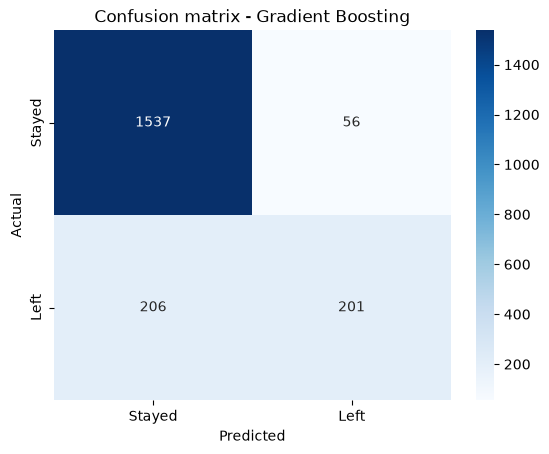

In [8]:
best_name = results_df.index[0]
best_model = models[best_name]
y_pred = best_model.predict(X_test_p)

print(f"Best model: {best_name}\n")
print(classification_report(y_test, y_pred, target_names=["Stayed", "Left"]))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Left"], yticklabels=["Stayed", "Left"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion matrix - {best_name}")
plt.show()

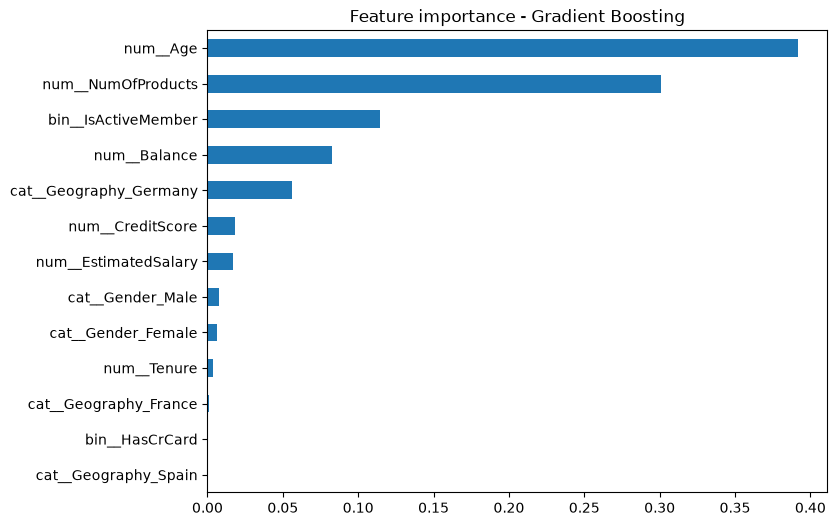

In [9]:

feature_names = preprocessor.get_feature_names_out()
importances = pd.Series(best_model.feature_importances_, index=feature_names).sort_values()

importances.plot(kind="barh", figsize=(8, 6))
plt.title(f"Feature importance - {best_name}")
plt.show()

#### Model training summary

- **Best model:** Gradient Boosting (ROC-AUC 0.870).
- **Tree-based vs linear models:** the tree-based ensembles (Gradient Boosting,
  CatBoost, Random Forest, AdaBoost, XGBoost) all scored higher ROC-AUC than
  Logistic Regression (0.775). This matches the EDA, which found non-linear
  patterns (age, number of products) and combined effects (age × activity)
  that a linear model cannot capture well.
- **Recall at default settings:** 0.494. The model caught only about half of
  the customers who left. Accuracy (0.869) looked high mainly because most
  customers stay.
- **Top features:** [your top 3–4 from the step 9 chart]. This [matches /
  partly matches] the EDA findings.
- **Class weighting:** recall improved from 0.494 to 0.757 for Gradient Boosting,
  while precision fell from 0.782 to 0.504. ROC-AUC stayed about the same (0.869).
- **Threshold:** the best F1 (0.637) was at a threshold of 0.30
  (recall 0.646, precision 0.628), compared with 0.605 at the default 0.50.

**Final choice for the pipeline:** Gradient Boosting trained normally, with a
decision threshold of 0.30. It has the best ROC-AUC and the best F1, and the
threshold can be adjusted to match the bank's tolerance for false alarms.

**Limitation:** the threshold was chosen using the test set, so its scores are
slightly optimistic.

#### Handling class imbalance
Only about 20% of customers left, so models learn mostly from customers
who stayed and miss many churners (low recall). Class weighting makes each
churner count more during training, so the model pays more attention to them.

In [10]:
from sklearn.utils.class_weight import compute_sample_weight

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

balanced_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(random_state=42, class_weight="balanced"),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", scale_pos_weight=neg / pos),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=False, auto_class_weights="Balanced"),
}

balanced_results = []
for name, model in balanced_models.items():
    if name == "Gradient Boosting":
        model.fit(X_train_p, y_train, sample_weight=compute_sample_weight("balanced", y_train))
    else:
        model.fit(X_train_p, y_train)
    y_pred = model.predict(X_test_p)
    y_proba = model.predict_proba(X_test_p)[:, 1]
    scores = evaluate_model(y_test, y_pred, y_proba)
    scores["Model"] = name
    balanced_results.append(scores)

balanced_df = pd.DataFrame(balanced_results).set_index("Model").sort_values("ROC_AUC", ascending=False).round(3)
balanced_df

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Gradient Boosting,0.799,0.504,0.757,0.605,0.869
CatBoost,0.814,0.532,0.713,0.609,0.858
Random Forest,0.842,0.617,0.582,0.599,0.847
XGBoost,0.821,0.552,0.636,0.591,0.830
Logistic Regression,0.714,0.387,0.700,0.499,0.777


**Findings:**
- Class weighting raised recall for every model. For Gradient Boosting, recall
  rose from 0.494 to 0.757, while precision fell from 0.782 to 0.504.
- ROC-AUC stayed almost the same for all models (Gradient Boosting 0.870 vs 0.869),
  so weighting did not change how well the models rank customers by risk.
  It only shifted where they draw the line between "stay" and "leave".
- Logistic Regression changed the most (recall 0.187 to 0.700), because without
  weighting it almost always predicted "stay".
- Weighted Gradient Boosting (recall 0.757, precision 0.504) behaves almost the
  same as the unweighted model with a threshold of 0.20 (recall 0.767,
  precision 0.511). Class weighting and lowering the threshold achieve a
  similar trade-off.
- Gradient Boosting remains the best model by ROC-AUC with or without weighting.

#### Decision threshold
By default a model predicts "leave" only if the probability is 50% or more.
Lowering this threshold flags more customers as at-risk, raising recall at the cost of precision. The right threshold is a business decision: how many false alarms the bank will accept to catch more churners.

In [11]:
best_model = models[results_df.index[0]]   

y_proba = best_model.predict_proba(X_test_p)[:, 1]

rows = []
for t in [0.5, 0.4, 0.3, 0.25, 0.2]:
    y_pred_t = (y_proba >= t).astype(int)
    rows.append({"Threshold": t,
                 "Precision": precision_score(y_test, y_pred_t),
                 "Recall": recall_score(y_test, y_pred_t),
                 "F1": f1_score(y_test, y_pred_t)})

pd.DataFrame(rows).round(3)

,Threshold,Precision,Recall,F1
0,0.50,0.782,0.494,0.605
1,0.40,0.713,0.550,0.621
2,0.30,0.628,0.646,0.637
3,0.25,0.569,0.698,0.627
4,0.20,0.511,0.767,0.614


**Findings:**
- Lowering the threshold from 0.50 to 0.30 raised recall from 0.494 to 0.646,
  while precision fell from 0.782 to 0.628.
- The best F1 (0.637) is at a threshold of 0.30. At this point the model
  catches about 65% of customers who leave, and about 63% of customers it
  flags actually leave.
- The final threshold is a business choice: a lower threshold catches more
  churners at the cost of more false alarms.
- Limitation: the threshold was chosen on the test set, so these scores are
  slightly optimistic. Ideally it would be chosen on a separate validation set.